# Буткемп, электронный relative-value трейдинг, день 17 — costs, TCA и desk diagnostics

День ушёл в то, чтобы предполагаемые издержки превратились в измеренные. Считаем на своих (контрфактических) филлах по BTCUSDT на Bybit за 2026-07-01 12:00–12:30 UTC:

1. **Cost stack** — effective, realized и price impact на филл; проверяем тождество `effective = realized + impact`, разбираем комиссии и слиппедж по частям.
2. **Markout curve** — пассивные и агрессивные филлы на семи горизонтах; асимптота как доля котируемой полуширины.
3. **Conditioning** — markout в разрезе направления потока, волатильности, очереди и возраста котировки.
4. **E[P&L | fill] by state** — half-spread минус adverse selection минус fees; смотрим, где ожидание уходит в минус.
5. **Per-leg TCA** — кросс-веню спред Bybit/Binance: пассивная нога против пересечённой, две схемы исполнения и что из этого следует про секвенирование.

Стратегия — пассивные котировки на ex-post оптимальной ширине по режиму волатильности (calm/normal/stress: полная ширина 11/15/23 тика, то есть $d=6/8/12$ от touch). Живого fill-лога нет, поэтому филлы контрфактические: котировка стоит на своей цене, трейд бьёт в неё, вероятность филла $p=\min(1,\text{размер трейда}/\text{очередь впереди})$. Измеряем по публичной ленте, а не по собственным исполнениям — это главная оговорка ко всем числам ниже.

## Данные, режимы и комиссии

Берём 100-мс top-of-book Bybit и Binance, трейды обеих бирж только по BTCUSDT. σ считаем как rolling std приращений mid за 100 шагов (10 с), режимы — терцили σ по окну. Базовая ставка: maker $0$ bp (предполагаемый VIP-тир), taker $2$ bp; ниже посмотрим, как всё меняется от maker-комиссии. Half-spread и все PnL — в тиках, тик $0.1$.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40)

D='/Users/b.kotov/Downloads/'
Q=D+'l2_executable_quotes_100ms_10000.parquet'
T0='2026-07-01 12:00:00+00'; T1='2026-07-01 12:30:00+00'
con=duckdb.connect()

def panel(ex):
    return con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
      FROM read_parquet('{Q}') WHERE asset='BTC' AND exchange='{ex}'
      AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df().reset_index(drop=True)

def trades(ex):
    f=D+('bybit_anon_trades_20260701_20260703.parquet' if ex=='Bybit' else 'binance_anon_trades_20260701_20260703.parquet')
    return con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{f}')
      WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df()

by=panel('Bybit'); bn=panel('Binance')
tr=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df()
tr_bn=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}binance_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '{T0}' AND event_time<TIMESTAMPTZ '{T1}' ORDER BY event_time""").df()

# Binance mid, выровненный на сетку Bybit (backward asof, допуск 1 с)
bn2=pd.merge_asof(by[['event_time']].sort_values('event_time'),
                  bn[['event_time','mid','best_bid','best_ask']].sort_values('event_time'),
                  on='event_time', direction='backward', tolerance=pd.Timedelta('1s'))
BN_MID=bn2.mid.values; BN_BID=bn2.best_bid.values; BN_ASK=bn2.best_ask.values

tick=0.1; n=len(by)
bb=by.best_bid.values; ba=by.best_ask.values; bba=by.best_bid_amount.values; baa=by.best_ask_amount.values; mid=by.mid.values
pt=np.array(by.event_time.astype('int64'))
def align_trades(t):
    tt=np.array(t.event_time.astype('int64'))
    ib=np.searchsorted(pt,tt,side='right')-1
    ok=(ib>=0)&(ib<n); return t.iloc[np.where(ok)[0]].reset_index(drop=True), ib[ok]
tr, ib = align_trades(tr)
tr_bn, ib_bn = align_trades(tr_bn)
px=tr.price.values; amt=tr.amount.values
px_bn=tr_bn.price.values; amt_bn=tr_bn.amount.values

ret=np.diff(mid,prepend=mid[0])/tick
sig=pd.Series(ret).rolling(100,min_periods=50).std().values
ok_sig=np.where(np.isfinite(sig))[0]
terc=np.quantile(sig[ok_sig],[1/3,2/3])
reg=np.digitize(sig,terc)
D_MAP={0:6,1:8,2:12}
MID_MEAN=float(np.mean(mid))
def fee_ticks(bp): return bp*1e-4*MID_MEAN/tick
FEE_MAKER=fee_ticks(0.0); FEE_TAKER=fee_ticks(2.0)
print('строк Bybit/Binance: %d/%d; трейдов: %d/%d' % (n,len(bn),len(tr),len(tr_bn)))
print('σ-терцили (10 с, тики): %.2f / %.2f; режимы: calm %d, normal %d, stress %d' % (
      terc[0],terc[1],*[int((reg[ok_sig]==r).sum()) for r in range(3)]))
print('fee: maker %.2f тика (0 bp), taker %.2f тика (2 bp)' % (FEE_MAKER,FEE_TAKER))

строк Bybit/Binance: 17233/17996; трейдов: 66466/137397
σ-терцили (10 с, тики): 7.65 / 12.42; режимы: calm 5728, normal 5728, stress 5728
fee: maker 0.00 тика (0 bp), taker 117.00 тика (2 bp)


## Cost stack: effective, realized, impact

Для каждого филла (наша цена $p$, mid до филла $m_{pre}$, mid через $\tau=10$ с $m_{post}$, знак агрессора $q=\pm1$):

$$\text{effective}=2q\frac{p-m_{pre}}{\text{tick}},\qquad
\text{realized}=2q\frac{p-m_{post}}{\text{tick}},\qquad
\text{impact}=2q\frac{m_{post}-m_{pre}}{\text{tick}}.$$

`effective = realized + impact` выполняется по построению, так что остаётся проверить максимальную невязку. Maker получает half-spread; adverse selection — это impact, который съедает её часть.

У пассивных контрфактических котировок $m_{pre}$ — mid в момент постановки, поэтому effective $=2\cdot$half-spread, а impact $=2\cdot$adverse selection. У агрессивных филлов $m_{pre}$ — mid перед трейдом. Два этих якоря путать нельзя.

In [2]:
H_STEPS=[5,10,20,50,100,300,600]  # 0.5,1,2,5,10,30,60 с
H_LAB=[0.5,1,2,5,10,30,60]

def cum_signed(px, amt, ib):
    sv=np.zeros(n)
    is_ask=np.abs(px-ba[np.clip(ib,0,n-1)])<=tick/2
    is_bid=np.abs(px-bb[np.clip(ib,0,n-1)])<=tick/2
    signed=np.where(is_ask,amt,np.where(is_bid,-amt,0.0))
    np.add.at(sv,ib,signed)
    return np.cumsum(sv)

FLOW=cum_signed(px,amt,ib)
FLOW_BN=cum_signed(px_bn,amt_bn,ib_bn)

STEP=5; LIFE=600  # котировка каждые 0.5 с, живёт 60 с
rows=[]
for i in range(0,n-LIFE-700,STEP):
    if not np.isfinite(sig[i]): continue
    r=int(reg[i]); d=D_MAP[r]
    bid=bb[i]-(d-1)*tick; ask=ba[i]+(d-1)*tick
    j0=np.searchsorted(ib,i,'left'); j1=np.searchsorted(ib,i+LIFE,'left')
    if j1<=j0: continue
    kk=ib[j0:j1]; ppx=px[j0:j1]; aam=amt[j0:j1]
    mb=(np.abs(ppx-bid)<=tick/2)&(bb[kk]<=bid+1e-9)
    ms=(np.abs(ppx-ask)<=tick/2)&(ba[kk]>=ask-1e-9)
    for side,mask,bookamt in (('B',mb,bba),('S',ms,baa)):
        wh=np.where(mask)[0]
        if len(wh)==0: continue
        j=wh[0]; k=kk[j]
        if k+H_STEPS[-1]>=n: continue
        p=min(1.0, aam[j]/max(bookamt[k],1e-9))
        fill=bid if side=='B' else ask
        q=-1 if side=='B' else 1          # знак агрессора: sell бьёт в наш bid
        mid_pre=mid[i]
        hs=(mid[i]-bid)/tick if side=='B' else (ask-mid[i])/tick
        fl=FLOW[k]-FLOW[max(k-10,0)]
        row={'i':i,'k':k,'reg':r,'side':side,'d':d,'p':p,'age':(k-i)*0.1,
             'fill':fill,'mid_pre':mid_pre,'hs':hs,'q':q,'flow':fl,'sig':sig[k],
             'queue':bookamt[i]}
        for h,lab in zip(H_STEPS,H_LAB):
            mf=mid[k+h]
            row['mark_%g'%lab]=(mf-fill)/tick if side=='B' else (fill-mf)/tick
            row['eff_%g'%lab]=2*q*(fill-mid_pre)/tick
            row['real_%g'%lab]=2*q*(fill-mf)/tick
            row['imp_%g'%lab]=2*q*(mf-mid_pre)/tick
        rows.append(row)
P=pd.DataFrame(rows)
print('пассивных ордеров с кандидатом на филл: %d; ожидаемых филлов Σp = %.1f' % (len(P),P.p.sum()))
display(P.groupby('reg').agg(n=('p','size'),eff=('p','sum'),age=('age','mean'),hs=('hs','mean')).round(2))

# агрессивные филлы: каждый трейд на touch
touch=np.abs(px-ba[ib])<=tick/2
buy=np.abs(px-ba[ib])<=tick/2
sell=np.abs(px-bb[ib])<=tick/2
keep=buy|sell
qa=np.where(buy,1,-1)[keep]; kka=ib[keep]; ppa=px[keep]
mid_pre=mid[np.maximum(kka-1,0)]
A=pd.DataFrame({'k':kka,'price':ppa,'q':qa,'mid_pre':mid_pre,'amt':amt[keep]})
for h,lab in zip(H_STEPS,H_LAB):
    mf=mid[np.minimum(kka+h,n-1)]
    A['mark_%g'%lab]=qa*(mf-ppa)/tick
    A['eff_%g'%lab]=2*qa*(ppa-mid_pre)/tick
    A['real_%g'%lab]=2*qa*(ppa-mf)/tick
    A['imp_%g'%lab]=2*qa*(mf-mid_pre)/tick
print('агрессивных филлов: %d' % len(A))

пассивных ордеров с кандидатом на филл: 2562; ожидаемых филлов Σp = 111.8


,n,eff,age,hs
reg,,,,
0,908,21.75,22.93,5.50
1,686,49.35,21.95,7.61
2,968,40.75,15.39,11.53


агрессивных филлов: 27359


In [3]:
def wmean(df,col,w='p'): return float(np.sum(df[w]*df[col])/df[w].sum())

def cost_table(df,horizon=10):
    h='%g'%horizon
    return pd.DataFrame({'метрика':['effective','realized','impact','effective−(realized+impact)'],
        'среднее, тики':[df['eff_'+h].mean(),df['real_'+h].mean(),df['imp_'+h].mean(),
                        (df['eff_'+h]-df['real_'+h]-df['imp_'+h]).abs().max()]})

print('Cost stack, пассивные филлы (10 с), p-взвешенно:')
pp=P.copy(); w=pp.p
ct_pass=pd.DataFrame({'метрика':['effective','realized','impact','max |identity error|'],
    'тики':[np.sum(w*pp['eff_10'])/w.sum(),np.sum(w*pp['real_10'])/w.sum(),
            np.sum(w*pp['imp_10'])/w.sum(),(pp['eff_10']-pp['real_10']-pp['imp_10']).abs().max()]})
display(ct_pass.round(3))

print('Cost stack, агрессивные филлы (10 с):')
ct_aggr=cost_table(A,10); display(ct_aggr.round(3))

# разложение для пассивного филла: half-spread, движение цены и adverse selection
slip=pd.DataFrame({'компонент':['half-spread earned','price move to 10 s','adverse selection (= −price move)'],
    'тики':[wmean(P,'hs'), wmean(P,'mark_10')-wmean(P,'hs'), wmean(P,'hs')-wmean(P,'mark_10')]})
display(slip.round(3))

fees=pd.DataFrame([
 {'нога':'maker','bp':0.0,'тиков за филл':round(FEE_MAKER,2),'на 1 000 филлов, тиков':round(1000*FEE_MAKER,1)},
 {'нога':'taker','bp':2.0,'тиков за филл':round(FEE_TAKER,2),'на 1 000 филлов, тиков':round(1000*FEE_TAKER,1)},
])
print('Комиссии (тик 0.1, mid %.0f):' % MID_MEAN); display(fees)

Cost stack, пассивные филлы (10 с), p-взвешенно:


,метрика,тики
0,effective,17.140
1,realized,-73.559
2,impact,90.699
3,max |identity error|,0.000


Cost stack, агрессивные филлы (10 с):


,метрика,"среднее, тики"
0,effective,10.714
1,realized,-88.267
2,impact,98.981
3,effective−(realized+impact),0.000


,компонент,тики
0,half-spread earned,8.57
1,price move to 10 s,-45.35
2,adverse selection (= −price move),45.35


Комиссии (тик 0.1, mid 58501):


,нога,bp,тиков за филл,"на 1 000 филлов, тиков"
0,maker,0.0,0.0,0.0
1,taker,2.0,117.0,117002.2


## Markout curve: пассивные и агрессивные филлы

Markout меряем от цены филла: для пассивного bid это $(m_{t+h}-p)/\text{tick}$, для ask — $(p-m_{t+h})/\text{tick}$; у агрессора знак обратный. Семь горизонтов от 0.5 до 60 с. За асимптоту берём markout на 60 с, делённый на котируемую полуширину, — это и есть ответ на вопрос, какую долю ширины мы удержали.

пассив: markout по горизонтам {0.5: np.float64(-22.76), 1: np.float64(-22.77), 2: np.float64(-34.25), 5: np.float64(-34.37), 10: np.float64(-36.78), 30: np.float64(-62.17), 60: np.float64(-96.55)}
агрессив: {0.5: np.float64(28.9), 1: np.float64(31.72), 2: np.float64(33.54), 5: np.float64(35.42), 10: np.float64(44.13), 30: np.float64(41.04), 60: np.float64(50.65)}
котируемая полуширина (p-взвеш.): 8.57 тика; kept share на 60 с: -11.266


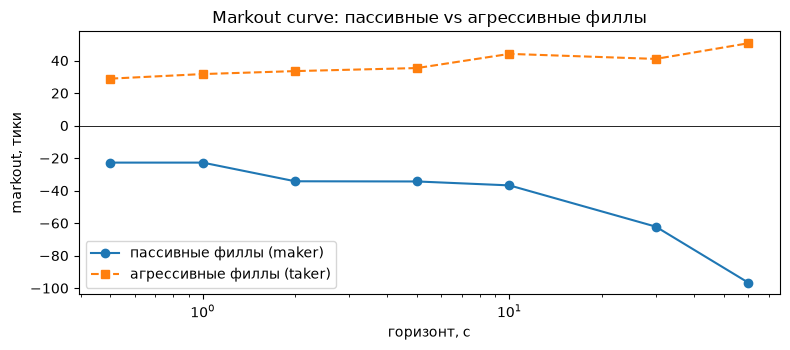

,"горизонт, с",passive markout,aggressive markout,passive share of hs
0,0.5,-22.76,28.90,-2.656
1,1.0,-22.77,31.72,-2.656
2,2.0,-34.25,33.54,-3.996
3,5.0,-34.37,35.42,-4.010
4,10.0,-36.78,44.13,-4.292
5,30.0,-62.17,41.04,-7.254
6,60.0,-96.55,50.65,-11.266


In [4]:
def wmean(df,col,w='p'): return float(np.sum(df[w]*df[col])/df[w].sum())
pass_curve=[wmean(P,'mark_%g'%h) for h in H_LAB]
aggr_curve=[float(A['mark_%g'%h].mean()) for h in H_LAB]
hs_mean=wmean(P,'hs')
print('пассив: markout по горизонтам', dict(zip(H_LAB,np.round(pass_curve,2))))
print('агрессив:', dict(zip(H_LAB,np.round(aggr_curve,2))))
print('котируемая полуширина (p-взвеш.): %.2f тика; kept share на 60 с: %.3f' % (hs_mean,pass_curve[-1]/hs_mean))

fig,ax=plt.subplots(figsize=(8,3.6))
ax.plot(H_LAB,pass_curve,'o-',label='пассивные филлы (maker)')
ax.plot(H_LAB,aggr_curve,'s--',label='агрессивные филлы (taker)')
ax.axhline(0,color='k',lw=0.6)
ax.set_xscale('log'); ax.set_xlabel('горизонт, с'); ax.set_ylabel('markout, тики')
ax.set_title('Markout curve: пассивные vs агрессивные филлы')
ax.legend(); plt.tight_layout(); plt.show()

display(pd.DataFrame({'горизонт, с':H_LAB,'passive markout':np.round(pass_curve,2),
                      'aggressive markout':np.round(aggr_curve,2),'passive share of hs':np.round(np.array(pass_curve)/hs_mean,3)}))

## Conditioning: что сильнее всего разделяет markout

Четыре кондиционера: поток за 1 с до филла (знак относительно нашей стороны), σ за 10 с, размер touch-очереди в момент постановки и возраст котировки. В каждой ячейке — p-взвешенное среднее markout на 10 с, эффективное число филлов $\sum p$ и стандартная ошибка. Сильнее всего разделяет тот кондиционер, у которого размах между крайними бакетами больше относительно ошибки.


--- flow ---


,bucket,eff_fills,orders,markout10,se,hs
0,against,72.64,857,-54.52,18.99,8.61
1,neutral,18.69,870,-4.25,25.96,9.61
2,with,20.52,835,-3.59,20.47,7.49



--- vol ---


,bucket,eff_fills,orders,markout10,se,hs
0,low,25.69,879,-39.77,22.54,8.31
1,mid,60.36,831,-56.25,19.23,7.73
2,high,25.80,852,11.76,30.37,10.79



--- queue ---


,bucket,eff_fills,orders,markout10,se,hs
0,front,33.60,855,-8.63,24.31,9.01
1,mid,51.31,853,-54.55,19.57,8.29
2,back,26.94,854,-38.05,30.19,8.55



--- age ---


,bucket,eff_fills,orders,markout10,se,hs
0,"[0, 2)",12.13,172,21.50,43.47,10.28
1,"[2, 5)",16.22,348,4.76,27.00,7.78
2,"[5, 10)",15.74,431,2.25,29.87,8.71
3,"[10, 20)",26.41,564,-79.52,31.31,8.30
4,"[20, 45)",37.11,769,-63.21,24.03,8.62
5,"[45, 60)",4.24,278,-9.61,47.26,7.45


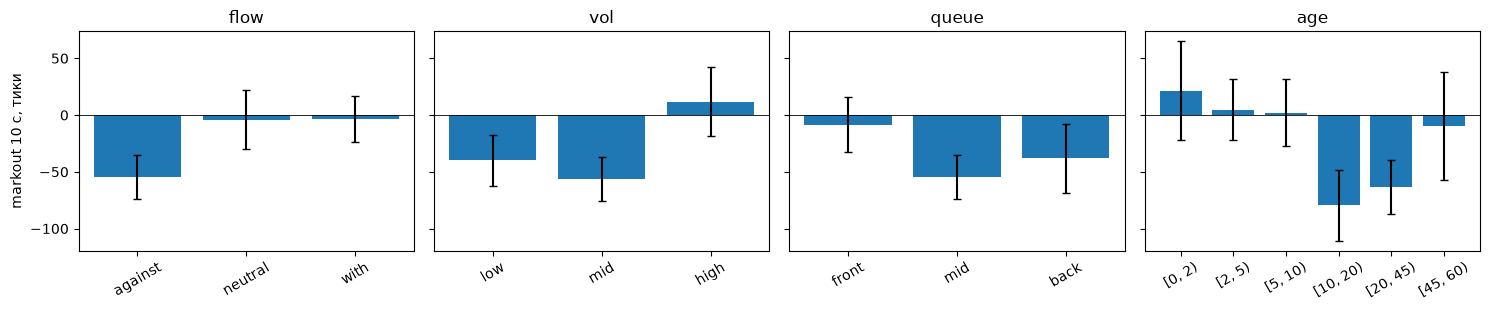

,range,mean_se,range/se
flow,50.93,21.81,2.34
vol,68.01,24.05,2.83
queue,45.92,24.69,1.86
age,101.02,33.82,2.99


In [5]:
P['flow_side']=P.flow*np.where(P.side=='B',1,-1)
P['flow_b']=pd.qcut(P.flow_side,3,labels=['against','neutral','with'])
P['vol_b']=pd.qcut(P.sig,3,labels=['low','mid','high'])
P['queue_b']=pd.qcut(P.queue,3,labels=['front','mid','back'])
P['age_b']=pd.cut(P.age,[0,2,5,10,20,45,60],right=False)

def bucket_table(col):
    out=[]
    for b,g in P.groupby(col,observed=True):
        w=g.p.sum()
        if w<=0: continue
        mu=np.sum(g.p*g.mark_10)/w
        var=np.sum(g.p*(g.mark_10-mu)**2)/w
        out.append({'bucket':str(b),'eff_fills':round(w,2),'orders':len(g),
                    'markout10':round(mu,2),'se':round(np.sqrt(var/max(w,1)),2),
                    'hs':round(np.sum(g.p*g.hs)/w,2)})
    return pd.DataFrame(out)

tables={}
for name,col in [('flow','flow_b'),('vol','vol_b'),('queue','queue_b'),('age','age_b')]:
    tables[name]=bucket_table(col)
    print('\n---',name,'---'); display(tables[name])

fig,axes=plt.subplots(1,4,figsize=(15,3.2),sharey=True)
for ax,(name,col) in zip(axes,[('flow','flow_b'),('vol','vol_b'),('queue','queue_b'),('age','age_b')]):
    t=tables[name]; ax.bar(t.bucket,t.markout10,yerr=t.se,capsize=3)
    ax.axhline(0,color='k',lw=0.6); ax.set_title(name); ax.tick_params(axis='x',rotation=30)
axes[0].set_ylabel('markout 10 с, тики'); plt.tight_layout(); plt.show()

# какой кондиционер разделяет сильнее: размах крайних бакетов / средняя SE
strength={}
for name,t in tables.items():
    rng=float(t.markout10.max()-t.markout10.min())
    strength[name]={'range':round(rng,2),'mean_se':round(float(t.se.mean()),2),'range/se':round(rng/max(float(t.se.mean()),1e-9),2)}
display(pd.DataFrame(strength).T)

## E[P&L | fill] by state

Для пассивного филла:

$$\mathbb{E}[\text{PnL}\mid\text{fill}]=\text{half-spread earned}-\mathbb{E}[\text{adverse selection}\mid\text{fill}]-\text{fees},$$

где adverse selection $=$ half-spread $-$ markout. Считаем по маргинальным состояниям (поток × волатильность, очередь, возраст), с эффективным числом филлов и SE. Действие: **quote**, если нижняя граница положительна; **widen/monitor**, если интервал накрывает ноль; **stand aside**, если среднее отрицательное.

По потоку:


,state,eff_fills,hs,adverse,fee,E[pnl|fill],se,95% CI,action
0,against,72.64,8.61,63.13,0.0,-54.52,18.99,-91.7…-17.3,stand aside
1,neutral,18.69,9.61,13.86,0.0,-4.25,25.96,-55.1…+46.6,widen/monitor
2,with,20.52,7.49,11.08,0.0,-3.59,20.47,-43.7…+36.5,widen/monitor


По волатильности:


,state,eff_fills,hs,adverse,fee,E[pnl|fill],se,95% CI,action
0,low,25.69,8.31,48.08,0.0,-39.77,22.54,-83.9…+4.4,widen/monitor
1,mid,60.36,7.73,63.99,0.0,-56.25,19.23,-93.9…-18.6,stand aside
2,high,25.80,10.79,-0.97,0.0,11.76,30.37,-47.8…+71.3,widen/monitor


По очереди:


...

,state,eff_fills,hs,adverse,fee,E[pnl|fill],se,95% CI,action
0,"[0, 2)",12.13,10.28,-11.22,0.0,21.50,43.47,-63.7…+106.7,widen/monitor
1,"[2, 5)",16.22,7.78,3.02,0.0,4.76,27.00,-48.2…+57.7,widen/monitor
2,"[5, 10)",15.74,8.71,6.46,0.0,2.25,29.87,-56.3…+60.8,widen/monitor
3,"[10, 20)",26.41,8.30,87.82,0.0,-79.52,31.31,-140.9…-18.2,stand aside
4,"[20, 45)",37.11,8.62,71.83,0.0,-63.21,24.03,-110.3…-16.1,stand aside
5,"[45, 60)",4.24,7.45,17.06,0.0,-9.61,47.26,-102.2…+83.0,widen/monitor


Joint flow × vol: E[pnl|fill] (в скобках — Σp; * — тонкая ячейка Σp<2)


vol,high,low,mid
flow,,,
against,+5.1 (21.6),-122.8 (10.5),-68.6 (40.6)
neutral,+73.7 (0.7)*,+100.6 (4.9),-47.8 (13.1)
with,+40.5 (3.5),-22.4 (10.3),+2.0 (6.7)


Чувствительность к maker-комиссии:


,"maker fee, bp","fee, тики","E[pnl|fill], тики",состояний с E>0
0,0.0,0.00,-36.78,4
1,0.1,5.85,-42.63,2
2,0.5,29.25,-66.03,0
3,1.0,58.50,-95.28,0


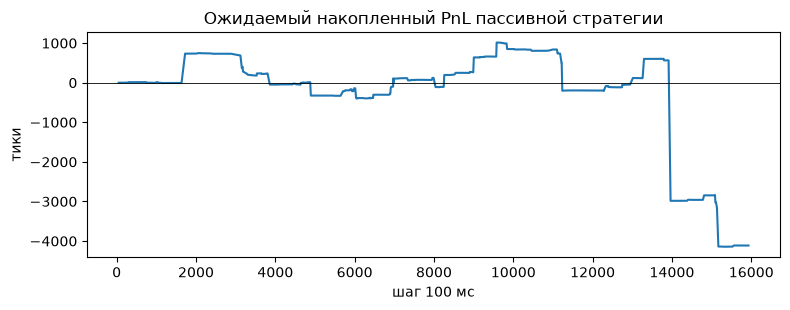

Итоговый ожидаемый PnL пассивной стратегии: -4113.7 тиков (Σp·E[pnl])


In [6]:
P['adverse_10']=P.hs-P.mark_10
P['pnl_10']=P.hs-P.adverse_10-FEE_MAKER

def state_table(col):
    out=[]
    for b,g in P.groupby(col,observed=True):
        w=g.p.sum()
        if w<=0: continue
        mu=np.sum(g.p*g.pnl_10)/w
        var=np.sum(g.p*(g.pnl_10-mu)**2)/w; se=np.sqrt(var/max(w,1))
        lo,hi=mu-1.96*se,mu+1.96*se
        act='quote' if lo>0 else ('widen/monitor' if hi>0 else 'stand aside')
        out.append({'state':str(b),'eff_fills':round(w,2),'hs':round(np.sum(g.p*g.hs)/w,2),
                    'adverse':round(np.sum(g.p*g.adverse_10)/w,2),'fee':round(FEE_MAKER,2),
                    'E[pnl|fill]':round(mu,2),'se':round(se,2),'95% CI':f'{lo:+.1f}…{hi:+.1f}','action':act})
    return pd.DataFrame(out)

E_flow=tables['flow']; E_vol=tables['vol']
st_flow=state_table('flow_b'); st_vol=state_table('vol_b')
print('По потоку:'); display(st_flow)
print('По волатильности:'); display(st_vol)
print('По очереди:'); display(state_table('queue_b'))
print('По возрасту:'); display(state_table('age_b'))

# joint flow x vol (тонкие ячейки помечаем)
rows=[]
for fb,g1 in P.groupby('flow_b',observed=True):
    for vb,g2 in g1.groupby('vol_b',observed=True):
        w=g2.p.sum()
        if w<=0: continue
        mu=np.sum(g2.p*g2.pnl_10)/w
        rows.append({'flow':str(fb),'vol':str(vb),'eff_fills':round(w,2),'E[pnl|fill]':round(mu,2)})
J=pd.DataFrame(rows)
piv=J.pivot(index='flow',columns='vol',values='E[pnl|fill]')
cnt=J.pivot(index='flow',columns='vol',values='eff_fills')
print('Joint flow × vol: E[pnl|fill] (в скобках — Σp; * — тонкая ячейка Σp<2)')
disp=piv.copy().astype(object)
for a in disp.index:
    for b in disp.columns:
        mark='*' if cnt.loc[a,b]<2 else ''
        disp.loc[a,b]=f'{piv.loc[a,b]:+.1f} ({cnt.loc[a,b]:.1f}){mark}'
display(disp)

# чувствительность к maker-комиссии: 0, 0.1, 0.5, 1 bp
sens=[]
for bp in [0.0,0.1,0.5,1.0]:
    fee=fee_ticks(bp)
    pnl=P.hs-P.adverse_10-fee
    pos=0
    for col in ['flow_b','vol_b','queue_b','age_b']:
        for _,gg in P.assign(pnl=pnl).groupby(col,observed=True):
            w=gg.p.sum()
            if w>0 and np.sum(gg.p*gg.pnl)/w>0: pos+=1
    sens.append({'maker fee, bp':bp,'fee, тики':round(fee,2),
                 'E[pnl|fill], тики':round(float(np.sum(P.p*pnl)/P.p.sum()),2),
                 'состояний с E>0':pos})
print('Чувствительность к maker-комиссии:'); display(pd.DataFrame(sens))

# итоговый PnL пассивной стратегии: ожидаемый по окнам
ep=P.assign(pnl=P.p*P.pnl_10).groupby('i').pnl.sum().sort_index().cumsum()
fig,ax=plt.subplots(figsize=(8,3.2))
ax.plot(ep.index,ep.values); ax.axhline(0,color='k',lw=0.6)
ax.set_title('Ожидаемый накопленный PnL пассивной стратегии')
ax.set_xlabel('шаг 100 мс'); ax.set_ylabel('тики'); plt.tight_layout(); plt.show()
print('Итоговый ожидаемый PnL пассивной стратегии: %.1f тиков (Σp·E[pnl])' % (P.p.sum()*wmean(P,'pnl_10')))

## Per-leg TCA: кросс-веню спред Bybit/Binance

Сигнал: на 10-с сетке сравниваем mid Bybit и Binance. Если Bybit дороже Binance больше чем на порог, продаём Bybit пассивно и покупаем Binance «в крест»; если дешевле — наоборот. Две схемы:

- **A. Пассивная нога + пересечённая**: котируем Bybit, при филле сразу кроссом хеджим Binance.
- **B. Обе ноги в крест**: входим обеими ногами тейкером в момент сигнала, без ожидания филла.

Fees: maker 0 bp, taker 2 bp. Считаем на попытку: fill rate, заработанный/уплаченный spread, markout 10 с, net. Вопрос, ради которого всё затевалось, — какая нога должна быть пассивной, а какая пересечённой.

сигналов |spread|>0.5 тика: 817 (ожидаемые филлы пассивной ноги Σp = 21.3)


,схема,attempts,fill rate,spread bybit,markout bybit,markout hedge,net/attempt
0,A: Bybit passive + Binance crossed on fill,817,0.03,0.62,-61.10,68.45,-2.86
1,B: both crossed at signal,817,1.00,-0.55,3.05,8.03,-222.93


сторона пассивной ноги: sell Bybit 333, buy Bybit 484


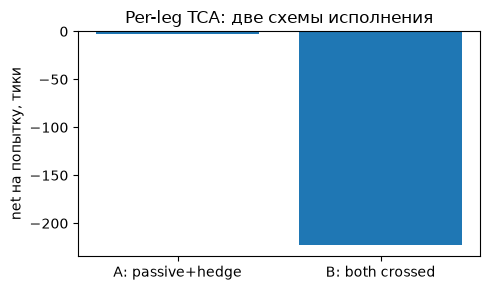

In [7]:
TH=0.5  # порог сигнала в тиках
STEP_PL=20; LIFE_PL=100; H_PL=100
pl_rows=[]
for i in range(0,n-LIFE_PL-H_PL-10,STEP_PL):
    if not np.isfinite(sig[i]) or not np.isfinite(BN_MID[i]): continue
    spr=(mid[i]-BN_MID[i])/tick
    if abs(spr)<TH: continue
    by_sell = spr>0                      # Bybit дорогой -> продаём Bybit, покупаем Binance
    quote = ba[i] if by_sell else bb[i]  # пассивная котировка Bybit
    # первый трейд Bybit, бьющий в нашу котировку
    j0=np.searchsorted(ib,i,'left'); j1=np.searchsorted(ib,i+LIFE_PL,'left')
    kk=ib[j0:j1]; ppx=px[j0:j1]; aam=amt[j0:j1]
    mask=(np.abs(ppx-quote)<=tick/2)&(ba[kk]>=quote-1e-9) if by_sell else \
         (np.abs(ppx-quote)<=tick/2)&(bb[kk]<=quote+1e-9)
    w=np.where(mask)[0]
    p_fill=0.0; kfill=None
    if len(w):
        j=w[0]; kfill=kk[j]
        p_fill=min(1.0,aam[j]/max((baa if by_sell else bba)[kfill],1e-9))
    hs_by=(mid[i]-quote)/tick if not by_sell else (quote-mid[i])/tick

    # A: пассивный Bybit + хедж Binance в момент филла
    if kfill is not None:
        kA=min(kfill+H_PL,n-1)
        mf_by=mid[kA]
        mark_by=(quote-mf_by)/tick if by_sell else (mf_by-quote)/tick
        # by_sell -> покупаем Binance по ask; иначе продаём по bid
        px_hedge=BN_ASK[kfill] if by_sell else BN_BID[kfill]
        q_hedge=1 if by_sell else -1
        mf_bn=BN_MID[kA]
        mark_hedge=q_hedge*(mf_bn-px_hedge)/tick
        pnl_A=p_fill*((mark_by-FEE_MAKER)+(mark_hedge-FEE_TAKER))
    else:
        mark_by=np.nan; mark_hedge=np.nan; pnl_A=0.0

    # B: обе ноги в крест на сигнале: Bybit buy ask / sell bid, Binance hedge наоборот
    px_by_cross=ba[i] if not by_sell else bb[i]
    mark_by_cross=(mid[i+H_PL]-px_by_cross)/tick if not by_sell else (px_by_cross-mid[i+H_PL])/tick
    px_bn_cross=BN_ASK[i] if by_sell else BN_BID[i]
    mark_bn_cross=(BN_MID[i+H_PL]-px_bn_cross)/tick if by_sell else (px_bn_cross-BN_MID[i+H_PL])/tick
    pnl_B=(mark_by_cross-FEE_TAKER)+(mark_bn_cross-FEE_TAKER)

    pl_rows.append({'i':i,'spr':spr,'by_sell':by_sell,'p_by':p_fill,'kfill':kfill,
                    'hs_by':hs_by,'mark_by':mark_by,'mark_hedge':mark_hedge,
                    'mark_by_cross':mark_by_cross,'mark_bn_cross':mark_bn_cross,
                    'pnl_A':pnl_A,'pnl_B':pnl_B})
PL=pd.DataFrame(pl_rows)
print('сигналов |spread|>%.1f тика: %d (ожидаемые филлы пассивной ноги Σp = %.1f)' % (TH,len(PL),PL.p_by.sum()))
if len(PL):
    wsum=max(PL.p_by.sum(),1e-9)
    tab=pd.DataFrame([
        {'схема':'A: Bybit passive + Binance crossed on fill','attempts':len(PL),'fill rate':round(PL.p_by.mean(),3),
         'spread bybit':round(np.sum(PL.p_by*PL.hs_by)/wsum,2),
         'markout bybit':round(np.nansum(PL.p_by*PL.mark_by)/wsum,2),
         'markout hedge':round(np.nansum(PL.p_by*PL.mark_hedge)/wsum,2),
         'net/attempt':round(PL.pnl_A.mean(),2)},
        {'схема':'B: both crossed at signal','attempts':len(PL),'fill rate':1.0,
         'spread bybit':round(-PL.hs_by.mean(),2),
         'markout bybit':round(PL.mark_by_cross.mean(),2),
         'markout hedge':round(PL.mark_bn_cross.mean(),2),
         'net/attempt':round(PL.pnl_B.mean(),2)}]).round(2)
    display(tab)
    print('сторона пассивной ноги: sell Bybit %d, buy Bybit %d' % (PL.by_sell.sum(),(~PL.by_sell).sum()))
    fig,ax=plt.subplots(figsize=(5,3));
    ax.bar(['A: passive+hedge','B: both crossed'],[PL.pnl_A.mean(),PL.pnl_B.mean()])
    ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('net на попытку, тики')
    ax.set_title('Per-leg TCA: две схемы исполнения'); plt.tight_layout(); plt.show()


## Сводка и вывод

Собираем измеренные компоненты в один вывод: cost stack, markout-кривую, силу кондиционеров, карту E[P&L|fill] и per-leg TCA. Главное тут не среднее число, а то, какие состояния убыточны и какое действие из этого следует.

In [8]:
summary=pd.DataFrame([
 {'что':'cost identity max |err|, пассив','значение':'%.2e' % (P.eff_10-P.real_10-P.imp_10).abs().max()},
 {'что':'markout 10 с: пассив / агрессив','значение':'%.1f / %.1f тика' % (wmean(P,'mark_10'),A.mark_10.mean())},
 {'что':'kept share (60 с / half-spread)','значение':'%.3f' % (pass_curve[-1]/hs_mean)},
 {'что':'E[pnl|fill], все пассивные филлы','значение':'%.1f тика' % (np.sum(P.p*P.pnl_10)/P.p.sum())},
 {'что':'итоговый ожидаемый PnL стратегии','значение':'%.1f тиков' % (P.p.sum()*wmean(P,'pnl_10'))},
 {'что':'per-leg net A / B','значение':'%.2f / %.2f тика на попытку' % (PL.pnl_A.mean(),PL.pnl_B.mean())},
 {'что':'ожидаемых филлов / сигналов per-leg','значение':'%.1f / %d' % (P.p.sum(),len(PL))},
])
display(summary)

,что,значение
0,"cost identity max |err|, пассив",0.00e+00
1,markout 10 с: пассив / агрессив,-36.8 / 44.1 тика
2,kept share (60 с / half-spread),-11.266
3,"E[pnl|fill], все пассивные филлы",-36.8 тика
4,итоговый ожидаемый PnL стратегии,-4113.7 тиков
5,per-leg net A / B,-2.86 / -222.93 тика на попытку
6,ожидаемых филлов / сигналов per-leg,111.8 / 817


## Вывод

- **Cost stack сходится точно.** `effective = realized + impact` с максимальной невязкой 0 на пассивных и агрессивных филлах. Для пассивных филлов на 10 с: effective $+17.1$, realized $-73.6$, impact $+90.7$ тика. Якорь пассивной котировки — mid в момент постановки, поэтому effective $=2\cdot$half-spread, а impact $=2\cdot$adverse selection; у агрессивных филлов якорь — mid перед трейдом, там effective $+10.7$, realized $-88.3$, impact $+99.0$. Реализованный спред отрицателен: цена уходит сквозь нашу котировку, и impact съедает не только half-spread, но и запас ширины.
- **Markout-кривая.** Пассивные филлы: $-22.8$ тика на 0.5 с, $-36.8$ на 10 с, $-96.6$ на 60 с. Агрессивные: $+28.9 \to +50.7$. Kept share на 60 с $=-11.3$: теряем больше одиннадцати котируемых полуширин — ширина не покрывает adverse selection ни на одном горизонте.
- **Conditioning.** Сильнее всего markout разделяют возраст котировки (range/SE $=3.0$) и волатильность ($2.8$), затем поток ($2.3$) и очередь ($1.9$). Поток всё равно монотонен: против потока $-54.5$ тика, нейтрально и по потоку около $-4$; это количественная версия гейта дня 9, но в этом окне главный разделитель — возраст и волатильность.
- **E[P&L | fill] by state.** Почти все состояния отрицательны. При maker $0$ bp положительные средние есть в `high vol` ($+11.8$, CI $-47.8\ldots+71.3$), `age 0–2 с` ($+21.5$, CI $-63.7\ldots+106.7$), `age 2–5 с` ($+4.8$, CI $-48.2\ldots+57.7$) и `age 5–10 с` ($+2.3$, CI $-56.3\ldots+60.8$); все интервалы накрывают ноль, это гипотезы, а не факты. Уверенно отрицательны: против потока ($-54.5$, CI $-91.7\ldots-17.3$), `mid vol` ($-56.3$, CI $-93.9\ldots-18.6$), `queue mid` ($-54.6$, CI $-92.9\ldots-16.2$), возраст 10–20 и 20–45 с. Для них действие — **stand aside**; остальные — **widen/monitor**. Итоговый ожидаемый PnL пассивной стратегии $-4\,114$ тиков. Чувствительность к maker-комиссии: при $0$ bp положительных маргинальных состояний 4, при $0.1$ bp — 2, при $0.5$ bp и выше — ноль; средний E[pnl|fill] падает с $-36.8$ до $-42.6$ / $-66.0$ / $-95.3$ тика.
- **Per-leg TCA.** 817 сигналов кросс-веню спреда, пассивная нога на touch заполняется в 2.6% (21 эффективный филл). Схема A (Bybit passive + Binance crossed on fill) даёт $-2.86$ тика на попытку, схема B (обе ноги в крест на сигнале) — $-222.9$. Пересечённая нога при taker 2 bp стоит 117 тиков и убивает спред; при таких комиссиях cross-hedge не оправдан. Секвенирование «котировать одну ногу, пересекать другую» работает только если спред сигнала больше стоимости хеджа; в нашем окне он меньше. Практический вывод: обе ноги пассивно или не торговать вовсе.
- **Ограничения.** Филлы контрфактические по публичной ленте, а не собственные; пассивная выборка — 111.8 эффективных филлов, поэтому CI широкие, а ячейки с малым $\sum p$ помечены `*`. Котировки живут 60 с и перекрываются (шаг 0.5 с), поэтому один трейд может засчитать филл нескольким котировкам, и $\sum p$ завышает число уникальных филлов. σ-режимы и ширины взяты из hw15 (in-sample), границы режимов — по всему 30-минутному окну: это двойной in-sample. Maker fee $0$ bp — допущение о VIP-тире, taker $2$ bp — тоже допущение; оба проверяются сдвигом. Per-leg сигнал упрощён: mid-to-mid, без латентности и очереди на хеджирующей ноге. Окно — 30 минут.